<a href="https://colab.research.google.com/github/autisanket25/Minor-Project/blob/main/Minor_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Import Libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

In [ ]:
from tensorflow.keras import layers, models

In [ ]:
print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


## 2. Load and Understand MNIST


In [ ]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
print('Training images:', x_train.shape)
print('Training labels:', y_train.shape)
print('Testing images:', x_test.shape)
print('Testing labels:', y_test.shape)
print('Classes:', np.unique(y_train))

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)
Classes: [0 1 2 3 4 5 6 7 8 9]


## 3. Display Sample Images

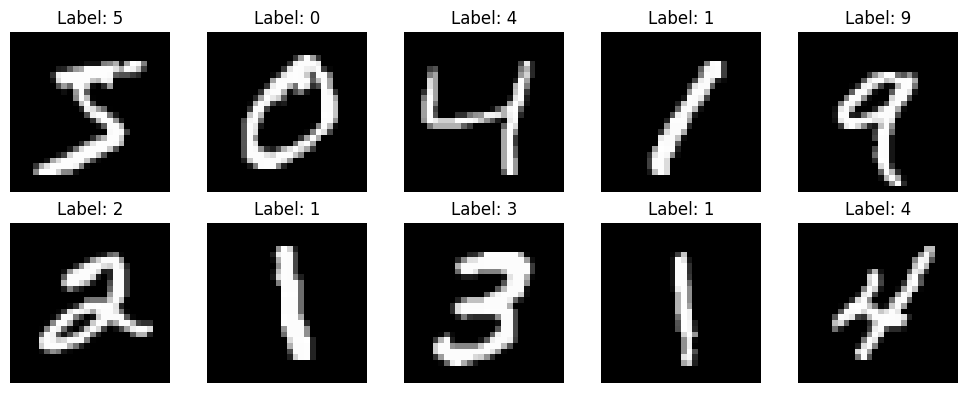

In [ ]:
plt.figure(figsize=(10,4))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f'Label: {y_train[i]}')
    plt.axis('off')
plt.tight_layout()
plt.show()

## 4. Preprocess Images


In [ ]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

In [ ]:
print('Processed training shape:', x_train.shape)
print('Processed testing shape:', x_test.shape)

Processed training shape: (60000, 28, 28, 1)
Processed testing shape: (10000, 28, 28, 1)


## 5. Build the CNN Model

In [ ]:
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Train the CNN

In [ ]:
history = model.fit(x_train, y_train, epochs=5, batch_size=64, validation_split=0.1)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 42s 48ms/step - accuracy: 0.9206 - loss: 0.2593 - val_accuracy: 0.9838 - val_loss: 0.0593
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 40s 47ms/step - accuracy: 0.9734 - loss: 0.0888 - val_accuracy: 0.9830 - val_loss: 0.0602
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 40s 47ms/step - accuracy: 0.9803 - loss: 0.0657 - val_accuracy: 0.9902 - val_loss: 0.0410
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 40s 47ms/step - accuracy: 0.9836 - loss: 0.0523 - val_accuracy: 0.9853 - val_loss: 0.0613
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 40s 47ms/step - accuracy: 0.9864 - loss: 0.0443 - val_accuracy: 0.9912 - val_loss: 0.0361


## 7. Training and Validation Accuracy

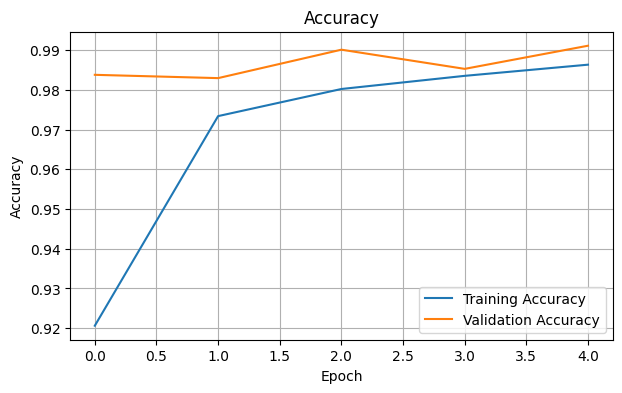

In [ ]:
plt.figure(figsize=(7,4))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy');
plt.title('Accuracy')
plt.legend(); plt.grid(True);
plt.show()

## 8. Training and Validation Loss

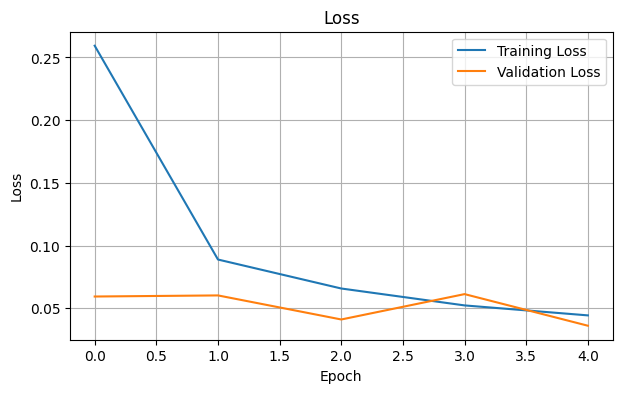

In [ ]:
plt.figure(figsize=(7,4))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss');
plt.title('Loss')
plt.legend(); plt.grid(True);
plt.show()

## 9. Evaluate on Test Data

In [ ]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

In [ ]:
print('Test Loss:', round(float(test_loss), 4))
print('Test Accuracy:', round(float(test_accuracy) * 100, 2), '%')

Test Loss: 0.0311
Test Accuracy: 98.96 %


## 10. Actual vs Predicted Labels

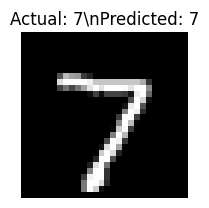

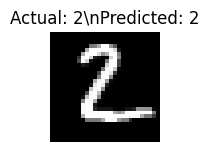

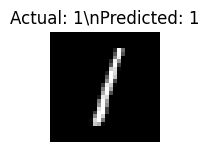

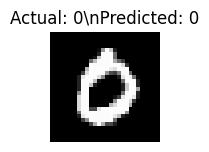

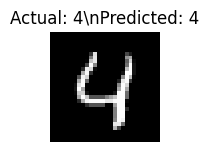

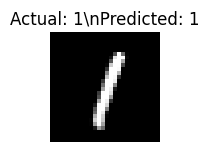

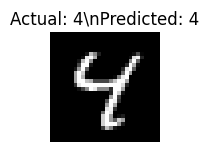

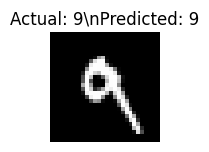

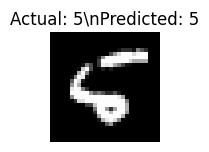

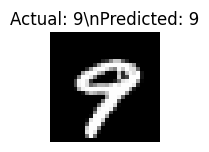

Actual: 7 | Predicted: 7
Actual: 2 | Predicted: 2
Actual: 1 | Predicted: 1
Actual: 0 | Predicted: 0
Actual: 4 | Predicted: 4
Actual: 1 | Predicted: 1
Actual: 4 | Predicted: 4
Actual: 9 | Predicted: 9
Actual: 5 | Predicted: 5
Actual: 9 | Predicted: 9


In [ ]:
predictions = np.argmax(model.predict(x_test[:10], verbose=0), axis=1)
plt.figure(figsize=(12,4))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_test[i].squeeze(), cmap='gray')
    plt.title(f'Actual: {y_test[i]}\\nPredicted: {predictions[i]}')
    plt.axis('off')
    plt.tight_layout();
    plt.show()
for i in range(10):
    print('Actual:', int(y_test[i]), '| Predicted:', int(predictions[i]))